In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Panel de establecimientos

La EAM sigue a las mismas plantas año tras año (`nordest`). Con {dd}`eam.panel()` se arma un panel listo
para econometría; antes conviene revisar que los identificadores se mantengan.

In [2]:
import numpy as np

import dane_data as dd

eam = dd.eam.load(range(2000, 2025))
superv = dd.eam.supervivencia(eam)
superv.tail(8).round(1)

,anio,siguiente,establecimientos,siguen_al_anio_siguiente,pct_siguen
16,2016,2017,8466,8051,95.1
17,2017,2018,8214,7789,94.8
18,2018,2019,7911,7569,95.7
19,2019,2020,7631,7270,95.3
20,2020,2021,7343,7094,96.6
21,2021,2022,7138,6711,94.0
22,2022,2023,6775,6605,97.5
23,2023,2024,6714,6420,95.6


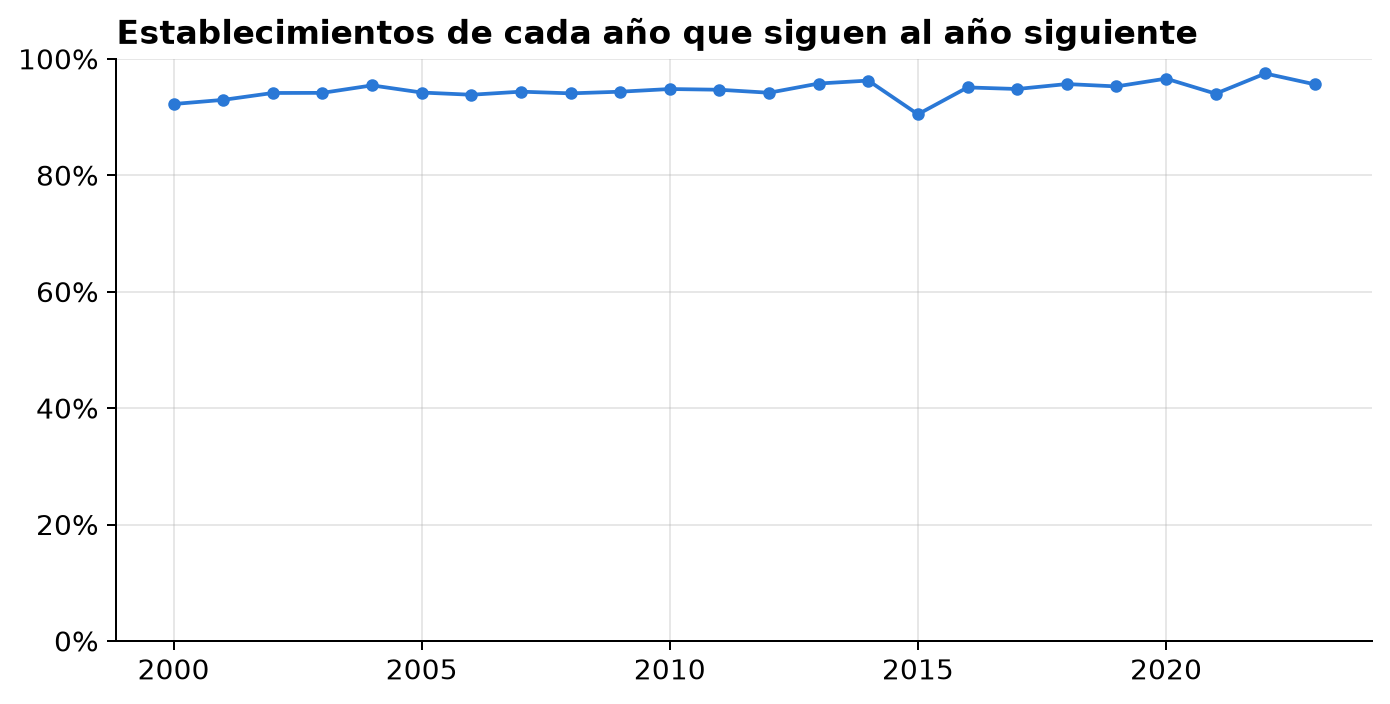

In [3]:
ax = superv.plot(x="anio", y="pct_siguen", marker="o", ms=4, legend=False)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 100)
ax.set_xlabel("")
ax.set_title("Establecimientos de cada año que siguen al año siguiente");

Todos los años, más del 90 % de los establecimientos sigue al año siguiente, sin caídas bruscas: los
identificadores se mantienen desde 2000. Si un año la proporción se desplomara, lo más probable sería un
cambio de identificadores entre catálogos del ANDA, no el cierre de las plantas, y un panel que cruce ese
año no seguiría a las mismas plantas.

## Un panel balanceado

In [4]:
panel = dd.eam.panel(eam, balanceado=True, anios=range(2012, 2025))
panel = panel[(panel["valagri"] > 0) & (panel["pertotal"] > 0)].copy()
panel["log_productividad"] = np.log(panel["valagri"] / panel["pertotal"])
panel.index.get_level_values("nordest").nunique(), len(panel)

(5428, 70506)

## Persistencia de la productividad

Las plantas más productivas un año lo siguen siendo al siguiente: la correlación de la productividad (en
logaritmos) entre un año y el siguiente es de 0,85.

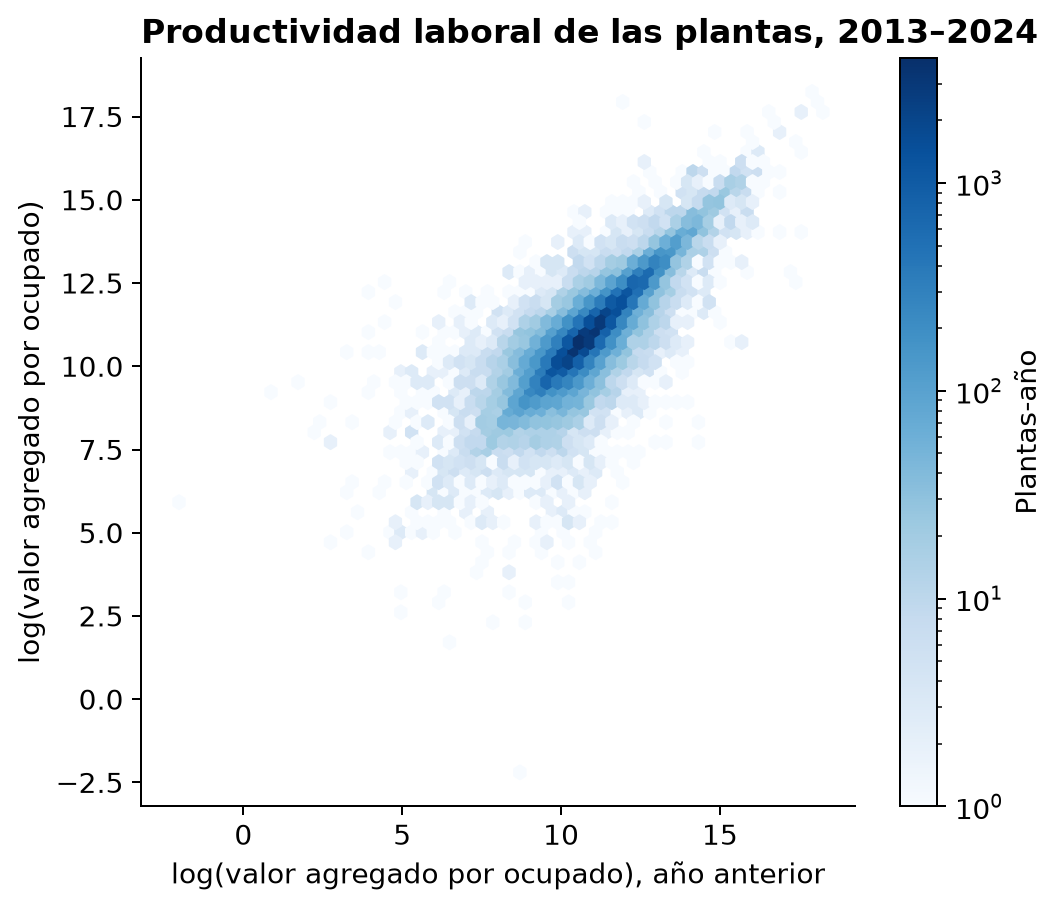

In [5]:
panel["log_productividad_anterior"] = panel.groupby(level="nordest")["log_productividad"].shift()
d = panel.dropna(subset=["log_productividad_anterior"])

fig, ax = plt.subplots(figsize=(6.4, 5.4))
hb = ax.hexbin(d["log_productividad_anterior"], d["log_productividad"], gridsize=60, mincnt=1, cmap="Blues", bins="log")
ax.set_xlabel("log(valor agregado por ocupado), año anterior")
ax.set_ylabel("log(valor agregado por ocupado)")
ax.set_title("Productividad laboral de las plantas, 2013–2024")
ax.grid(False)
fig.colorbar(hb, ax=ax, label="Plantas-año");

In [6]:
d[["log_productividad", "log_productividad_anterior"]].corr().round(3)

,log_productividad,log_productividad_anterior
log_productividad,1.000,0.846
log_productividad_anterior,0.846,1.000


## Dispersión entre plantas

La razón entre el percentil 90 y el 10 de la productividad mide qué tan distintas son las plantas:

In [7]:
p = panel.groupby(level="anio")["log_productividad"].quantile([0.1, 0.9]).unstack()
(np.exp(p[0.9] - p[0.1])).round(1).rename("p90/p10")

anio
2012    10.3
2013    10.5
2014    10.5
2015    10.8
2016    10.9
2017    10.7
2018    10.8
2019    11.5
2020    15.1
2021    13.0
2022    13.7
2023    13.1
2024    11.6
Name: p90/p10, dtype: float64

```{tip}
El panel tiene índice (`nordest`, `anio`): se puede pasar directamente a `linearmodels.PanelOLS` para
estimar modelos con efectos fijos.
```